# Breast Cancer Diagnosis — Malignant vs Benign Classification

A supervised machine learning project that classifies breast tumor biopsies as **malignant** or **benign** using the Wisconsin Diagnostic Breast Cancer (WDBC) dataset.

**Goal:** given 30 numeric features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass (radius, texture, perimeter, area, smoothness, etc.), predict whether the tumor is malignant or benign.

**Tools:** NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

sns.set_style("whitegrid")
np.random.seed(42)


## 1. Load and explore the dataset

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["diagnosis"] = data.target  # 0 = malignant, 1 = benign
df["diagnosis_label"] = df["diagnosis"].map({0: "malignant", 1: "benign"})

print("Dataset shape:", df.shape)
print("\nClass balance:")
print(df["diagnosis_label"].value_counts())
df.head()


Dataset shape: (569, 32)

Class balance:
diagnosis_label
benign       357
malignant    212
Name: count, dtype: int64


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension  diagnosis diagnosis_label
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119   

In [3]:
df.describe().T[["mean", "std", "min", "max"]].head(10)


                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744

## 2. Visualize feature relationships

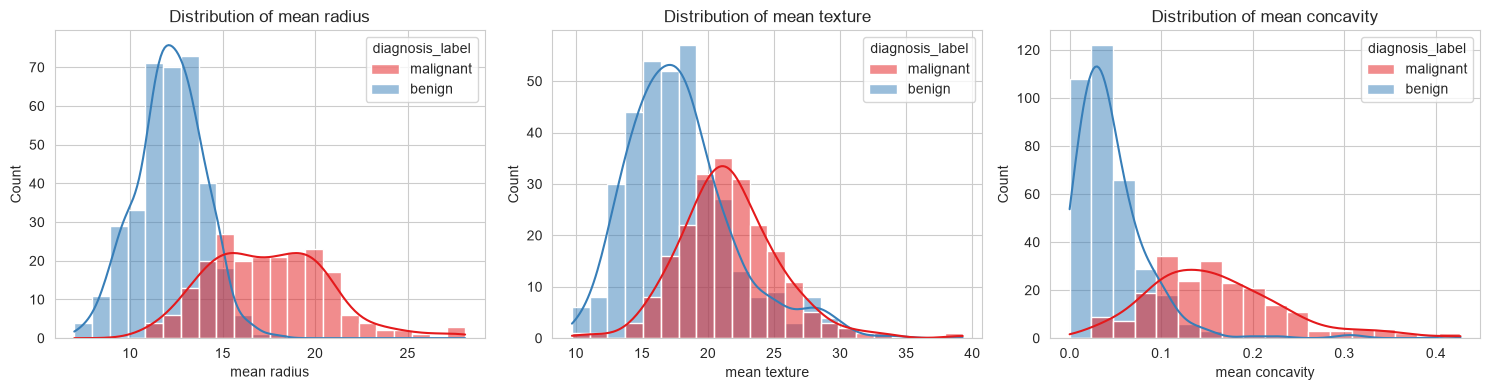

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["mean radius", "mean texture", "mean concavity"]):
    sns.histplot(data=df, x=feature, hue="diagnosis_label", kde=True, ax=ax, palette="Set1")
    ax.set_title(f"Distribution of {feature}")
plt.tight_layout()
plt.savefig("feature_distributions.png", dpi=120)
plt.show()


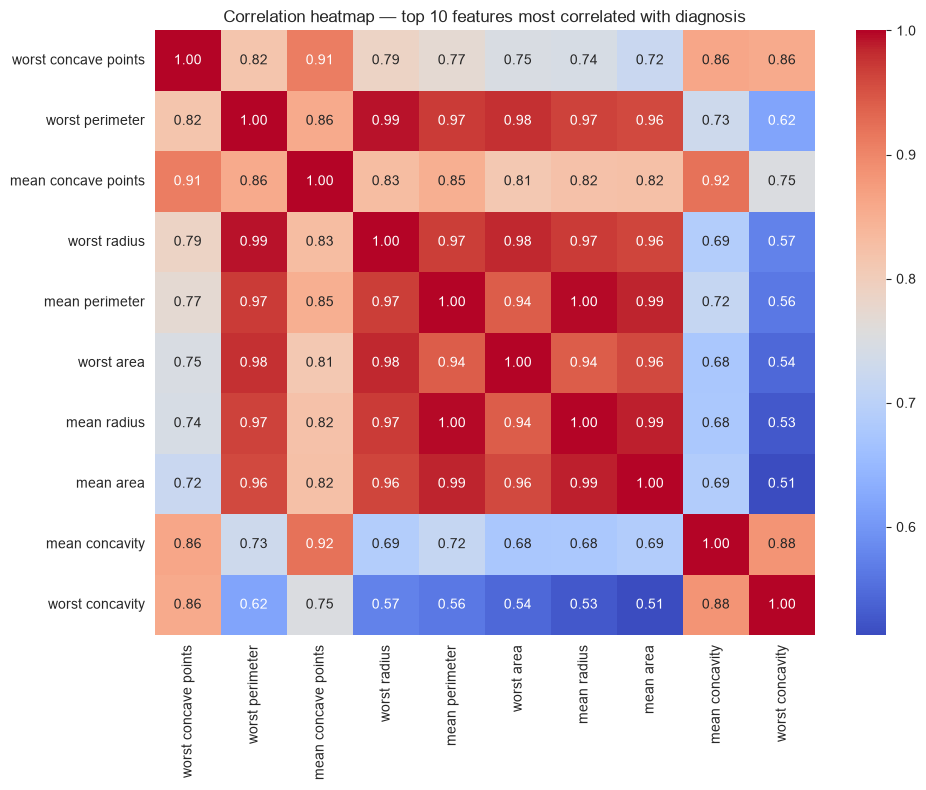

In [5]:
plt.figure(figsize=(10, 8))
top_corr_features = df.corr(numeric_only=True)["diagnosis"].abs().sort_values(ascending=False).index[1:11]
sns.heatmap(df[top_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap — top 10 features most correlated with diagnosis")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=120)
plt.show()


## 3. Train/test split and feature scaling

In [6]:
X = df[data.feature_names]
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])


Train size: 455  Test size: 114


## 4. Train models: Logistic Regression and Random Forest

In [7]:
log_reg = LogisticRegression(max_iter=5000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

def evaluate(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, y_pred_lr, y_proba_lr),
    evaluate("Random Forest", y_test, y_pred_rf, y_proba_rf),
])
results


                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.982456   0.986111  0.986111  0.986111  0.995370
1        Random Forest  0.956140   0.958904  0.972222  0.965517  0.993056

## 5. Confusion matrices

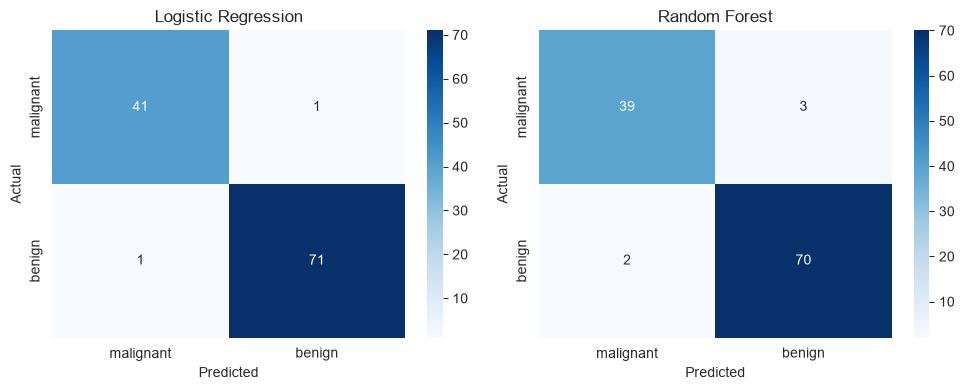

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, preds) in zip(axes, [("Logistic Regression", y_pred_lr), ("Random Forest", y_pred_rf)]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=120)
plt.show()


## 6. ROC curves

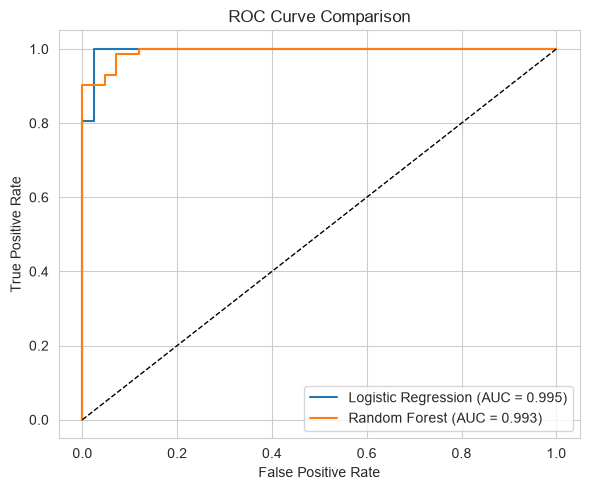

In [9]:
plt.figure(figsize=(6, 5))
for name, y_proba in [("Logistic Regression", y_proba_lr), ("Random Forest", y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=120)
plt.show()


## 7. Most important features (Random Forest)

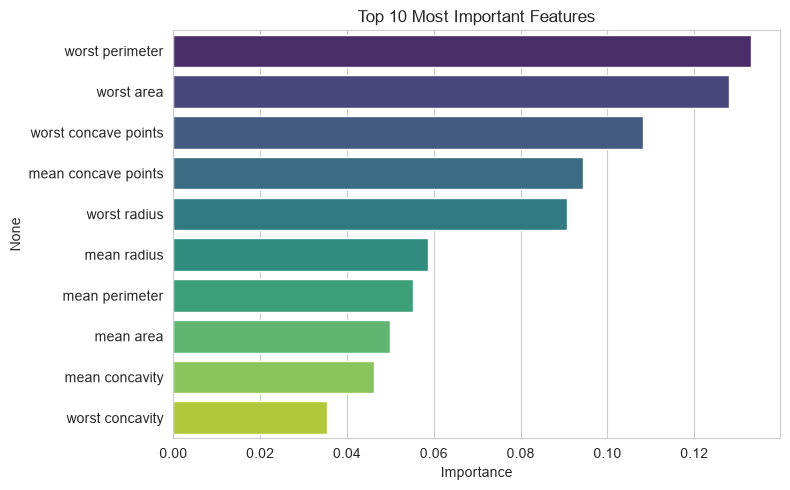

worst perimeter         0.133100
worst area              0.128052
worst concave points    0.108107
mean concave points     0.094414
worst radius            0.090639
mean radius             0.058662
mean perimeter          0.055242
mean area               0.049938
mean concavity          0.046207
worst concavity         0.035357
dtype: float64

In [10]:
importances = pd.Series(rf.feature_importances_, index=data.feature_names).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Top 10 Most Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=120)
plt.show()
importances


## 8. Summary

Both models were trained on the Wisconsin Diagnostic Breast Cancer dataset (569 samples, 30 features) to classify tumors as malignant or benign.

Final test-set performance is reported in the results table above (Section 4). The Random Forest's feature importances show that the features most predictive of malignancy are concentrated around cell size and concavity measurements (e.g. `worst perimeter`, `worst concave points`, `mean concave points`), consistent with the clinical intuition that malignant tumors tend to be larger and more irregularly shaped.

This notebook demonstrates an end-to-end supervised classification workflow: data loading, exploratory data analysis, preprocessing, model training, and evaluation using multiple metrics (accuracy, precision, recall, F1, ROC-AUC).
